# Heart Disease Severity Prediction — Complete ML Pipeline

**Dataset:** UCI Heart Disease (920 rows, 14 columns)  
**Target:** num (0 = no disease … 4 = very severe)

## Pipeline Overview

1. Imports & configuration
2. Data loading
3. Data cleaning
4. Exploratory data analysis (EDA)
5. Feature engineering
6. Data preprocessing
7. Train / holdout split
8. Custom clinical scorer
9. Model building (pipelines with SMOTE)
10. Nested cross-validation (hyperparameter search + unbiased eval)
11. Model selection & refit on full training set
12. Clinical threshold tuning (classes 3 & 4)
13. SHAP explainability
14. Final holdout evaluation
15. Visualisations (confusion matrix, recall, CV vs holdout)

## Step 1: Imports & Configuration

Import all required libraries and set global configuration variables.

In [7]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    cross_val_predict,
    train_test_split,
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
    make_scorer,
)

# imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("Installed all the necessary libraries and modules.")
print("HEART DISEASE SEVERITY PREDICTION — ML PIPELINE")


Note: you may need to restart the kernel to use updated packages.
Installed all the necessary libraries and modules.
HEART DISEASE SEVERITY PREDICTION — ML PIPELINE


In [8]:
# ── Global settings ──────────────────────────────────────────────────────────
SEED        = 42
TEST_SIZE   = 0.20          # 80 / 20 split
N_OUTER     = 5             # outer CV folds
N_INNER     = 3             # inner CV folds (hyperparameter search)
MIN_PREC    = 0.30          # minimum acceptable precision when tuning thresholds

FEATURES = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalch", "exang", "oldpeak", "slope", "ca", "thal",
]
TARGET   = "num"

CLASS_NAMES  = ["No Disease", "Mild", "Moderate", "Severe", "Very Severe"]
SEV_WEIGHTS  = {0: 1.0, 1: 1.5, 2: 2.0, 3: 3.0, 4: 4.0}

np.random.seed(SEED)

print(f"Configuration set: SEED={SEED}, TEST_SIZE={TEST_SIZE}")
print(f"CV configuration: {N_OUTER} outer × {N_INNER} inner folds")
print(f"Features: {len(FEATURES)} original features + engineered features")
print(f"Classes: {CLASS_NAMES}")
print(f"Severity weights: {SEV_WEIGHTS}")

Configuration set: SEED=42, TEST_SIZE=0.2
CV configuration: 5 outer × 3 inner folds
Features: 13 original features + engineered features
Classes: ['No Disease', 'Mild', 'Moderate', 'Severe', 'Very Severe']
Severity weights: {0: 1.0, 1: 1.5, 2: 2.0, 3: 3.0, 4: 4.0}


## Step 2: Data Loading

Load the UCI Heart Disease dataset and display basic information.

In [9]:

print("STEP 1 │ DATA LOADING")


df = pd.read_csv("heart_disease_uci.csv")  

print(f"  Shape          : {df.shape}")
print(f"  Columns        : {list(df.columns)}")
print(f"\n  Target distribution:\n{df[TARGET].value_counts().sort_index()}")
print(f"\n  Missing values per column:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f"\n  Data types:\n{df.dtypes}")

STEP 1 │ DATA LOADING
  Shape          : (920, 16)
  Columns        : ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

  Target distribution:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

  Missing values per column:
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64

  Data types:
id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object


## Step 3: Data Cleaning

Remove duplicates, standardise columns, and apply deterministic plausibility-based range clipping.


In [10]:
print("\n" + "─" * 65)
print("STEP 2 │ DATA CLEANING")
print("─" * 65)

before = len(df)
df.drop_duplicates(inplace=True)
print(f"  Duplicate rows removed : {before - len(df)}")

df.columns = df.columns.str.strip().str.lower()

NUMERIC_COLS   = ["age", "trestbps", "chol", "thalch", "oldpeak"]
CATEGORY_COLS  = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

print("\n  Missing values retained for training-stage imputation:")
missing_counts = df[NUMERIC_COLS + CATEGORY_COLS].isnull().sum()
print(missing_counts[missing_counts > 0].to_string())

print("\n  Plausibility-based range clipping:")
clips = {
    "chol"    : (100, 600),
    "trestbps": (60,  220),
    "thalch"  : (60,  220),
    "oldpeak" : (0,   10),
    "age"     : (20,  100),
}

for col, (lo, hi) in clips.items():
    n_low  = (df[col] < lo).sum()
    n_high = (df[col] > hi).sum()
    df[col] = df[col].clip(lo, hi)
    if n_low or n_high:
        print(f"    {col:10s}  [{lo}, {hi}]  →  {n_low} below + {n_high} above clipped")

print(f"\n  Final shape after cleaning : {df.shape}")



─────────────────────────────────────────────────────────────────
STEP 2 │ DATA CLEANING
─────────────────────────────────────────────────────────────────
  Duplicate rows removed : 0

  Missing values retained for training-stage imputation:
trestbps     59
chol         30
thalch       55
oldpeak      62
fbs          90
restecg       2
exang        55
slope       309
ca          611
thal        486

  Plausibility-based range clipping:
    chol        [100, 600]  →  173 below + 1 above clipped
    trestbps    [60, 220]  →  1 below + 0 above clipped
    oldpeak     [0, 10]  →  12 below + 0 above clipped

  Final shape after cleaning : (920, 16)


## Step 4: Exploratory Data Analysis (EDA)

Descriptive statistics and comprehensive visualizations.

In [11]:

print("STEP 3 │ EXPLORATORY DATA ANALYSIS")


print("\n  Descriptive statistics (numeric):")
print(df[NUMERIC_COLS].describe().round(2).to_string())

print("\n  Class balance:")
vc = df[TARGET].value_counts().sort_index()
for cls, count in vc.items():
    bar = "█" * int(count / 10)
    print(f"    Class {cls} ({CLASS_NAMES[cls]:12s}) : {count:4d}  {bar}")

STEP 3 │ EXPLORATORY DATA ANALYSIS

  Descriptive statistics (numeric):
          age  trestbps    chol  thalch  oldpeak
count  920.00    861.00  890.00  865.00   858.00
mean    53.51    132.20  218.47  137.55     0.89
std      9.42     18.69   78.24   25.93     1.07
min     28.00     60.00  100.00   60.00     0.00
25%     47.00    120.00  175.00  120.00     0.00
50%     54.00    130.00  223.00  140.00     0.50
75%     60.00    140.00  268.00  157.00     1.50
max     77.00    200.00  600.00  202.00     6.20

  Class balance:
    Class 0 (No Disease  ) :  411  █████████████████████████████████████████
    Class 1 (Mild        ) :  265  ██████████████████████████
    Class 2 (Moderate    ) :  109  ██████████
    Class 3 (Severe      ) :  107  ██████████
    Class 4 (Very Severe ) :   28  ██


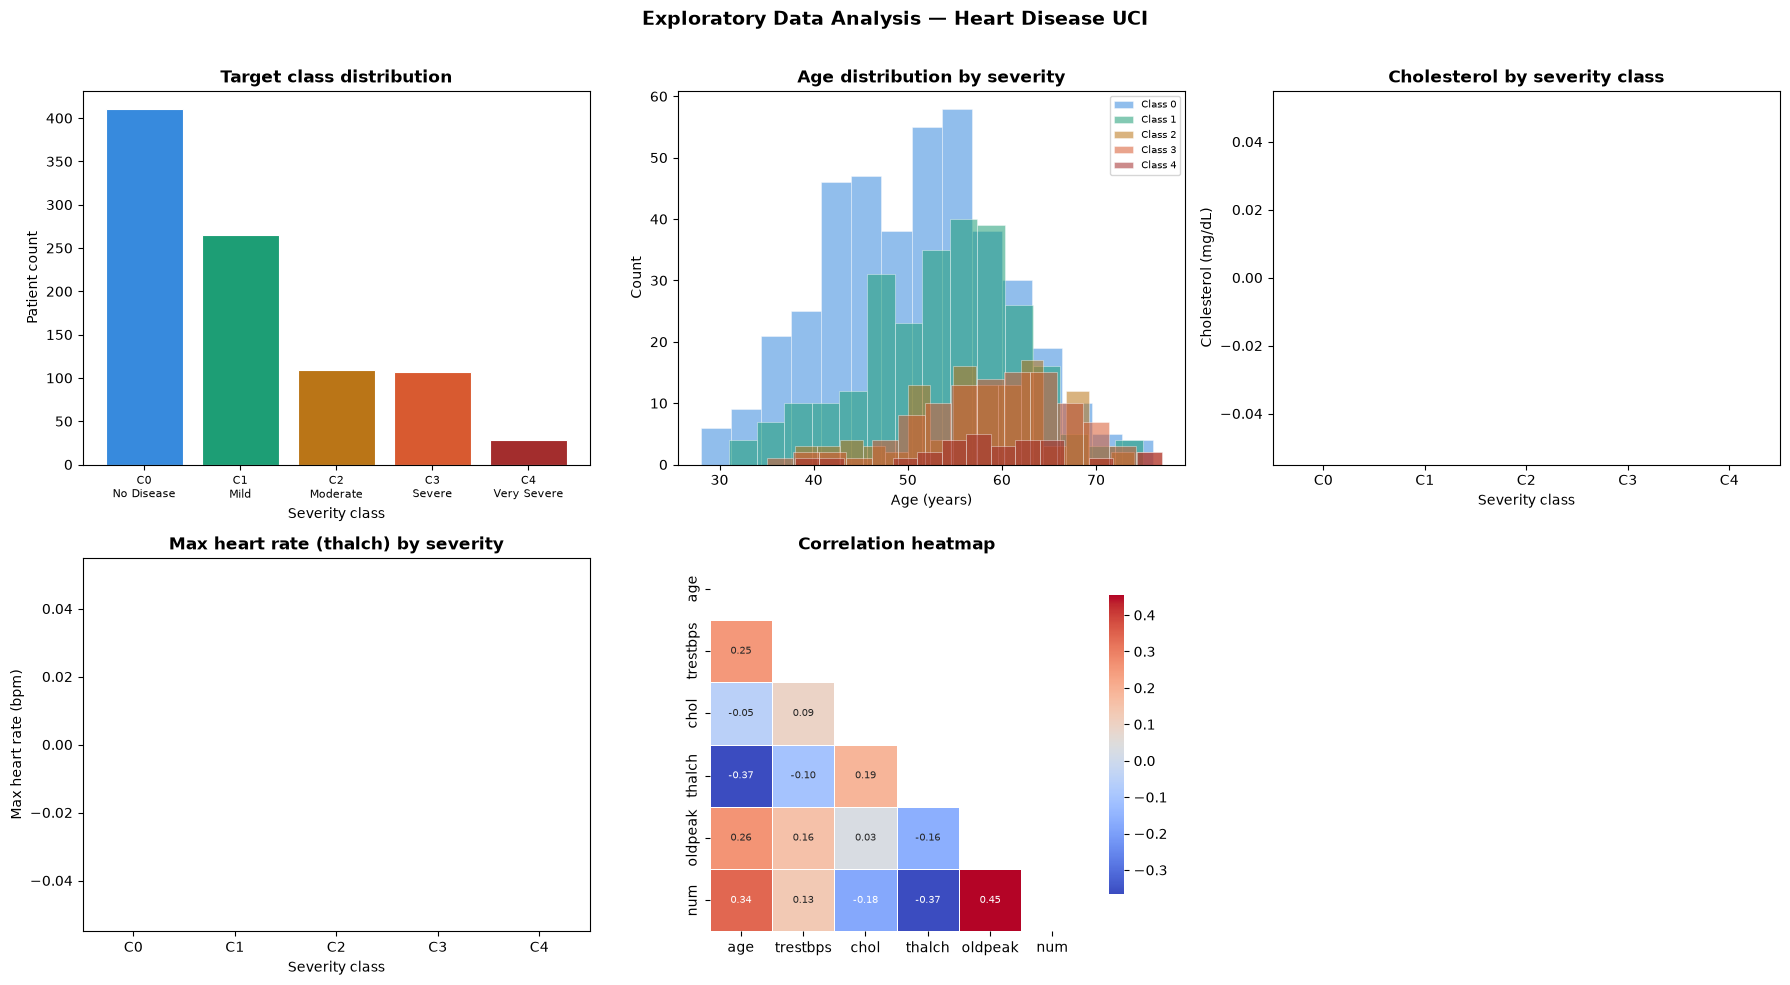


  EDA analytics:
  • Target distribution: the dataset is imbalanced, so the model should use class-aware metrics and balanced validation instead of accuracy alone.
  • Age: older patients tend to show higher disease severity, which makes age a strong cardiovascular risk indicator.
  • Cholesterol (chol): higher cholesterol levels are associated with more severe heart conditions, but some overlap across classes suggests it is a contributing factor rather than a standalone diagnosis signal.
  • Max heart rate (thalch): lower maximum heart rates during exercise are often linked with more severe cases, reflecting reduced cardiac performance or stress burden.
  • Correlation heatmap: the strongest relationships are the variables most useful for risk prediction; weaker or inconsistent correlations often represent supporting features instead of primary drivers.
  • Feature meaning: age = patient age in years; chol = serum cholesterol in mg/dL; thalch = maximum heart rate achieved during exer

In [ ]:
# ── EDA Visualizations — split into standalone figures ──────────────────────
colors = ["#378ADD", "#1D9E75", "#BA7517", "#D85A30", "#A32D2D"]

# 1) Target class distribution
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(vc.index, vc.values, color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Target class distribution", fontweight="bold")
ax.set_xlabel("Severity class")
ax.set_ylabel("Patient count")
ax.set_xticks(range(5))
ax.set_xticklabels([f"C{i}\n{CLASS_NAMES[i]}" for i in range(5)], fontsize=8)
plt.tight_layout()
plt.savefig("eda_target_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# 2) Age distribution by severity
fig, ax = plt.subplots(figsize=(7, 5))
for cls in range(5):
    subset = df[df[TARGET] == cls]["age"]
    ax.hist(subset, bins=15, alpha=0.55, color=colors[cls],
            label=f"Class {cls}", edgecolor="white", linewidth=0.5)
ax.set_title("Age distribution by severity", fontweight="bold")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Count")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("eda_age_by_severity.png", dpi=200, bbox_inches="tight")
plt.show()

# 3) Cholesterol by severity class (plotting only; original df remains unchanged)
fig, ax = plt.subplots(figsize=(7, 5))
chol_vals = df["chol"].fillna(df["chol"].mean())
data_by_class = [chol_vals[df[TARGET] == c].values for c in range(5)]
print("  Cholesterol boxplot: 30 missing values mean-filled for visualization only.")
bp = ax.boxplot(data_by_class, patch_artist=True, notch=False,
                medianprops=dict(color="white", linewidth=2))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title("Cholesterol by severity class", fontweight="bold")
ax.set_xlabel("Severity class")
ax.set_ylabel("Cholesterol (mg/dL)")
ax.set_xticklabels([f"C{i}" for i in range(5)])
plt.tight_layout()
plt.savefig("eda_cholesterol_by_severity.png", dpi=200, bbox_inches="tight")
plt.show()

# 4) Max heart rate by severity class (plotting only; original df remains unchanged)
fig, ax = plt.subplots(figsize=(7, 5))
thalch_vals = df["thalch"].fillna(df["thalch"].mean())
data_hr = [thalch_vals[df[TARGET] == c].values for c in range(5)]
print("  Max heart rate boxplot: 55 missing values mean-filled for visualization only.")
bp2 = ax.boxplot(data_hr, patch_artist=True,
                 medianprops=dict(color="white", linewidth=2))
for patch, color in zip(bp2["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title("Max heart rate (thalch) by severity", fontweight="bold")
ax.set_xlabel("Severity class")
ax.set_ylabel("Max heart rate (bpm)")
ax.set_xticklabels([f"C{i}" for i in range(5)])
plt.tight_layout()
plt.savefig("eda_maxhr_by_severity.png", dpi=200, bbox_inches="tight")
plt.show()

# 5) Correlation heatmap
fig, ax = plt.subplots(figsize=(7, 5))
corr = df[NUMERIC_COLS + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=ax, cmap="coolwarm", annot=True,
            fmt=".2f", linewidths=0.5, square=True,
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 7})
ax.set_title("Correlation heatmap", fontweight="bold")
plt.tight_layout()
plt.savefig("eda_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# 6) Sex by severity class
fig, ax = plt.subplots(figsize=(7, 5))
sex_by_class = pd.crosstab(df[TARGET], df["sex"]).reindex(range(5), fill_value=0)
sex_by_class.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"], edgecolor="white")
ax.set_title("Sex by severity class", fontweight="bold")
ax.set_xlabel("Severity class")
ax.set_ylabel("Count")
ax.set_xticklabels([f"C{i}\n{CLASS_NAMES[i]}" for i in range(5)], rotation=0)
ax.legend(title="Sex", labels=["Female", "Male"])
plt.tight_layout()
plt.savefig("eda_sex_by_severity.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved EDA figures: eda_target_distribution.png, eda_age_by_severity.png, eda_cholesterol_by_severity.png, eda_maxhr_by_severity.png, eda_correlation_heatmap.png, eda_sex_by_severity.png")

print("\n  EDA analytics:")
print("  • Target distribution: the dataset is imbalanced, so the model should use class-aware metrics and balanced validation instead of accuracy alone.")
print("  • Age: older patients tend to show higher disease severity, which makes age a strong cardiovascular risk indicator.")
print("  • Cholesterol (chol): higher cholesterol levels are associated with more severe heart conditions, but some overlap across classes suggests it is a contributing factor rather than a standalone diagnosis signal.")
print("  • Max heart rate (thalch): lower maximum heart rates during exercise are often linked with more severe cases, reflecting reduced cardiac performance or stress burden.")
print("  • Correlation heatmap: the strongest relationships are the variables most useful for risk prediction; weaker or inconsistent correlations often represent supporting features instead of primary drivers.")
print("  • Feature meaning: age = patient age in years; chol = serum cholesterol in mg/dL; thalch = maximum heart rate achieved during exercise; target = severity class from 0 to 4, where higher values indicate greater disease severity.")
print("  • Clinical takeaway: age, cholesterol, and exercise stress indicators carry predictive signal for heart disease severity, while class imbalance and overlapping distributions justify balanced metrics and careful model validation.")

## Step 5: Feature Engineering

Create deterministic, domain-informed rule-based engineered features. Missing source values are retained and imputed later inside the training pipeline.


In [ ]:
print("\n" + "─" * 65)
print("STEP 4 │ FEATURE ENGINEERING")
print("─" * 65)

df["age_group"] = pd.cut(
    df["age"], bins=[20, 40, 55, 65, 100], labels=[0, 1, 2, 3]
).astype("float")

df["cp_risk"] = np.where(
    df["cp"].isna(), np.nan, df["cp"].isin([0, 3]).astype(float)
)
df["high_hr"] = np.where(
    df["thalch"].isna(), np.nan, (df["thalch"] > 150).astype(float)
)
df["hypertension"] = np.where(
    df["trestbps"].isna(), np.nan, (df["trestbps"] > 140).astype(float)
)
df["oldpeak_cat"] = pd.cut(
    df["oldpeak"], bins=[-0.1, 0.5, 2.0, 10.0], labels=[0, 1, 2]
).astype("float")

print("  age_group   : binned [<40, 40-55, 55-65, >65] → 0/1/2/3")
print("  cp_risk     : 1 if cp ∈ {typical angina, asymptomatic} else 0")
print("  high_hr     : 1 if max HR > 150 bpm else 0")
print("  hypertension: 1 if resting BP > 140 mmHg else 0")
print("  oldpeak_cat : ST depression bins [normal, mild, severe] → 0/1/2")
print("  Missing source values remain missing and are handled after the train/holdout split.")

ENGINEERED = ["age_group", "cp_risk", "high_hr", "hypertension", "oldpeak_cat"]
ALL_FEATURES = FEATURES + ENGINEERED
print(f"\n  Total features : {len(FEATURES)} original + {len(ENGINEERED)} engineered = {len(ALL_FEATURES)}")



─────────────────────────────────────────────────────────────────
STEP 4 │ FEATURE ENGINEERING
─────────────────────────────────────────────────────────────────
  age_group   : binned [<40, 40-55, 55-65, >65] → 0/1/2/3
  cp_risk     : 1 if cp ∈ {typical angina, asymptomatic} else 0
  high_hr     : 1 if max HR > 150 bpm else 0
  hypertension: 1 if resting BP > 140 mmHg else 0
  oldpeak_cat : ST depression bins [normal, mild, severe] → 0/1/2
  Missing source values remain missing and are handled after the train/holdout split.

  Total features : 13 original + 5 engineered = 18


## Step 4.1: Feature Engineering Visualization — Pairplot

Visualize relationships between engineered features and target variable.

STEP 4.1 │ ENGINEERED FEATURES PAIRPLOT


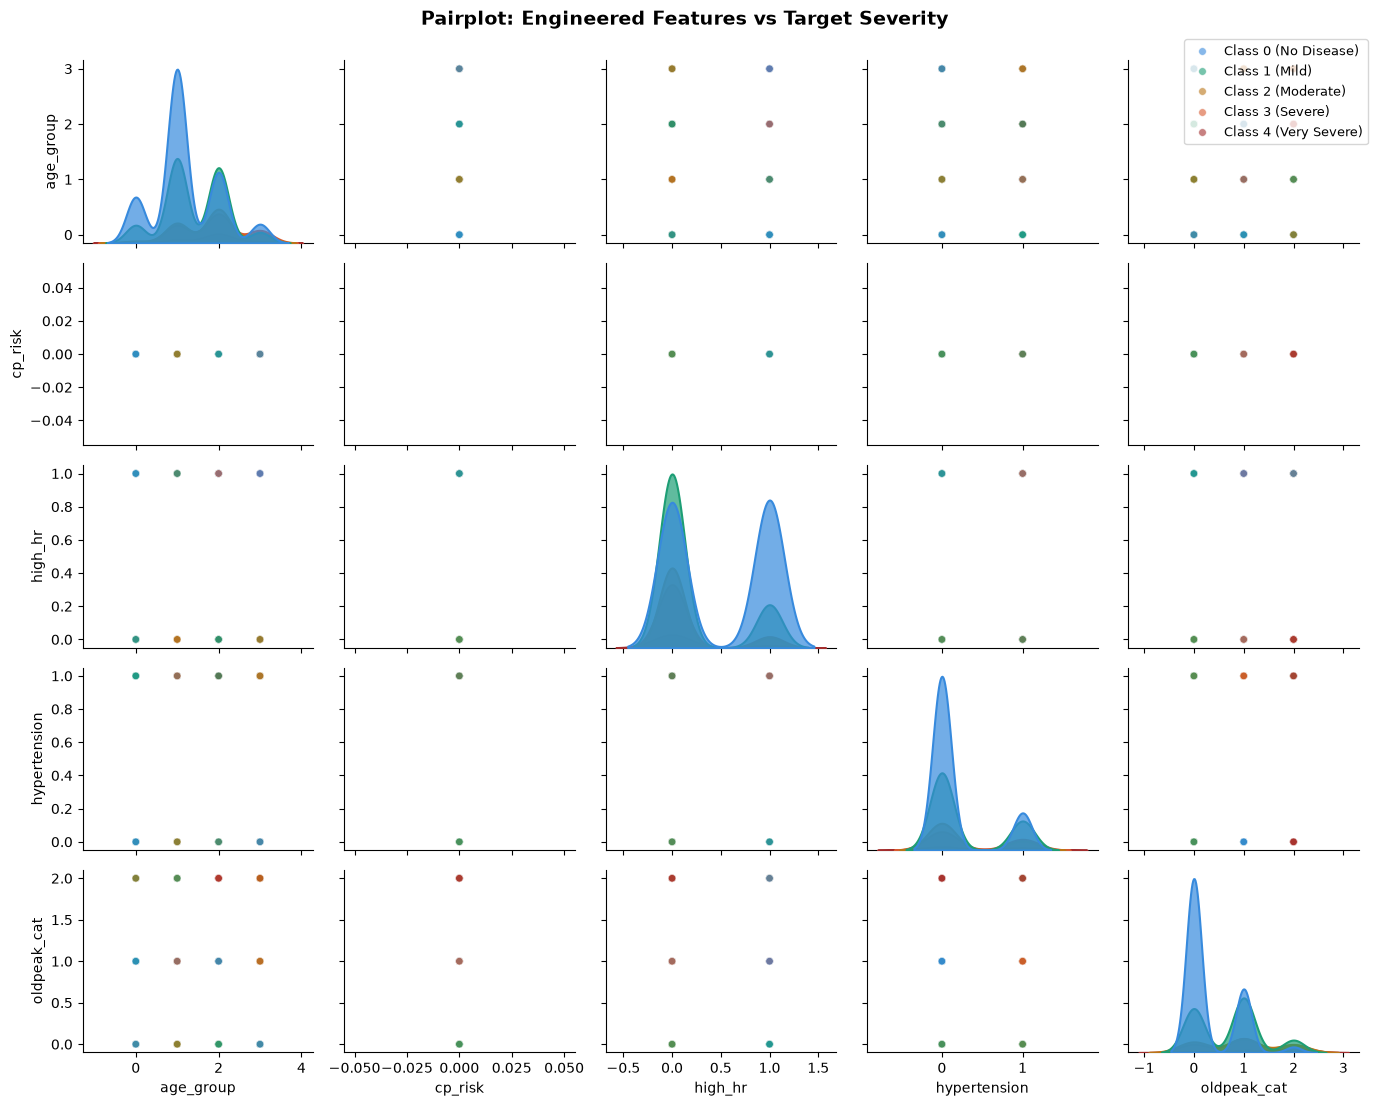

  Pairplot saved → engineered_features_pairplot.png
  Features visualized: ['age_group', 'cp_risk', 'high_hr', 'hypertension', 'oldpeak_cat']


In [ ]:
print("STEP 4.1 │ ENGINEERED FEATURES PAIRPLOT")

# Create a dataframe with engineered features and target for visualization
eng_features_df = df[ENGINEERED + [TARGET]].copy()

# Create pairplot with color-coded target classes
fig = sns.pairplot(
    eng_features_df,
    hue=TARGET,
    palette=colors,
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "s": 30, "edgecolor": "white", "linewidth": 0.5},
    diag_kws={"alpha": 0.7, "linewidth": 1.5},
    height=2.2,
    aspect=1.2,
)

fig.fig.suptitle(
    "Pairplot: Engineered Features vs Target Severity",
    fontsize=14,
    fontweight="bold",
    y=1.001,
)

# Customize legend
handles = fig._legend_data.values()
labels = [f"Class {i} ({CLASS_NAMES[i]})" for i in range(5)]
fig._legend.remove()
fig.fig.legend(
    handles=handles,
    labels=labels,
    loc="upper right",
    bbox_to_anchor=(1.0, 0.98),
    fontsize=9,
)

plt.tight_layout()
plt.savefig("engineered_features_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Pairplot saved → engineered_features_pairplot.png")
print(f"  Features visualized: {ENGINEERED}")


## Step 6: Train / Holdout Split

Stratified 80/20 split with locked holdout set. The split occurs before any data-dependent preprocessing.


In [ ]:
print("\n" + "─" * 65)
print("STEP 5 │ STRATIFIED TRAIN / HOLDOUT SPLIT  (80 / 20)")
print("─" * 65)

X = df[ALL_FEATURES].copy()
y = df[TARGET].values

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED,
)

print(f"  Training set  : {X_train.shape[0]} samples")
print(f"  Holdout set   : {X_holdout.shape[0]} samples  ← LOCKED until final eval")
print(f"\n  Train class distribution   : {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"  Holdout class distribution : {dict(zip(*np.unique(y_holdout, return_counts=True)))}")



─────────────────────────────────────────────────────────────────
STEP 5 │ STRATIFIED TRAIN / HOLDOUT SPLIT  (80 / 20)
─────────────────────────────────────────────────────────────────
  Training set  : 736 samples
  Holdout set   : 184 samples  ← LOCKED until final eval

  Train class distribution   : {np.int64(0): np.int64(329), np.int64(1): np.int64(212), np.int64(2): np.int64(87), np.int64(3): np.int64(86), np.int64(4): np.int64(22)}
  Holdout class distribution : {np.int64(0): np.int64(82), np.int64(1): np.int64(53), np.int64(2): np.int64(22), np.int64(3): np.int64(21), np.int64(4): np.int64(6)}


## Step 7: Data Preprocessing

Define data-dependent imputation and categorical encoding inside the training pipeline. These transformations are fitted only on training folds.


In [ ]:
print("\n" + "─" * 65)
print("STEP 6 │ DATA PREPROCESSING")
print("─" * 65)

NUMERIC_FEATURES = NUMERIC_COLS + ENGINEERED
CATEGORICAL_FEATURES = CATEGORY_COLS

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)

print(f"  Numeric features       : {len(NUMERIC_FEATURES)}")
print(f"  Categorical features  : {len(CATEGORICAL_FEATURES)}")
print("  Numeric imputation     : median (fit on training folds only)")
print("  Categorical imputation : mode (fit on training folds only)")
print("  Categorical encoding   : OrdinalEncoder (fit on training folds only)")



─────────────────────────────────────────────────────────────────
STEP 6 │ DATA PREPROCESSING
─────────────────────────────────────────────────────────────────
  Numeric features       : 10
  Categorical features  : 8
  Numeric imputation     : median (fit on training folds only)
  Categorical imputation : mode (fit on training folds only)
  Categorical encoding   : OrdinalEncoder (fit on training folds only)


## Step 8: Custom Clinical Scorer

Severity-weighted F1 that prioritizes correct prediction of severe cases.

In [ ]:
print("\n" + "─" * 65)
print("STEP 7 │ SEVERITY-WEIGHTED F1 SCORER")
print("─" * 65)

def severity_weighted_f1(y_true, y_pred):
    """
    Per-class F1 scores are dotted with normalised severity weights.
    A Class-4 error contributes 4× more than a Class-0 error.
    """
    per_class_f1 = f1_score(
        y_true, y_pred,
        average=None,
        labels=[0, 1, 2, 3, 4],
        zero_division=0,
    )
    w = np.array([SEV_WEIGHTS[i] for i in range(5)])
    w_norm = w / w.sum()
    return float(np.dot(per_class_f1, w_norm))

severity_scorer = make_scorer(severity_weighted_f1)
print("  Weights:", SEV_WEIGHTS)


─────────────────────────────────────────────────────────────────
STEP 7 │ SEVERITY-WEIGHTED F1 SCORER
─────────────────────────────────────────────────────────────────
  Weights: {0: 1.0, 1: 1.5, 2: 2.0, 3: 3.0, 4: 4.0}


## Step 9: Model Building — Pipelines with SMOTE

Define three model pipelines: SVM, Random Forest, and MLP.

In [ ]:
print("\n" + "─" * 65)
print("STEP 8 │ MODEL PIPELINES  (Preprocessing → SMOTE → Scaler → Classifier)")
print("─" * 65)

svm_pipe = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("scaler", StandardScaler()),
    ("clf", SVC(probability=True, class_weight="balanced", random_state=SEED)),
])
svm_param_grid = {
    "clf__C": [0.1, 1.0, 10.0],
    "clf__kernel": ["rbf", "linear"],
    "clf__gamma": ["scale", "auto"],
}

rf_pipe = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
])
rf_param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [10, 20, None],
    "clf__min_samples_split": [2, 5],
    "clf__max_features": ["sqrt", "log2"],
}

mlp_pipe = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(max_iter=500, random_state=SEED, early_stopping=True)),
])
mlp_param_grid = {
    "clf__hidden_layer_sizes": [(64, 32), (128, 64), (64, 32, 16)],
    "clf__alpha": [0.0001, 0.001],
    "clf__activation": ["relu", "tanh"],
    "clf__learning_rate_init": [0.001, 0.0005],
}

MODEL_REGISTRY = {
    "SVM": (svm_pipe, svm_param_grid),
    "Random Forest": (rf_pipe, rf_param_grid),
    "MLP": (mlp_pipe, mlp_param_grid),
}
print("  Registered 3 models: SVM, Random Forest, MLP")



─────────────────────────────────────────────────────────────────
STEP 8 │ MODEL PIPELINES  (Preprocessing → SMOTE → Scaler → Classifier)
─────────────────────────────────────────────────────────────────
  Registered 3 models: SVM, Random Forest, MLP


## Step 10: Nested Cross-Validation

Outer folds for honest generalization estimates, inner folds for hyperparameter tuning.

In [ ]:
print("\n" + "─" * 65)
print("STEP 9 │ NESTED CROSS-VALIDATION")
print(f"         Outer {N_OUTER}-fold  ×  Inner {N_INNER}-fold  (SMOTE inside each inner fold)")
print("─" * 65)

outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=SEED)

nested_results   = {}   # CV metrics per model
inner_estimators = {}   # GridSearchCV objects (used for refitting)

for name, (pipe, param_grid) in MODEL_REGISTRY.items():
    print(f"\n  ▶ {name}")

    grid_search = GridSearchCV(
        pipe, param_grid,
        cv=inner_cv,
        scoring=severity_scorer,
        n_jobs=-1,
        refit=True,
    )

    cv_result = cross_validate(
        grid_search,
        X_train, y_train,
        cv=outer_cv,
        scoring={
            "accuracy":    "accuracy",
            "macro_f1":    make_scorer(f1_score, average="macro", zero_division=0),
            "severity_f1": severity_scorer,
        },
        return_train_score=False,
        n_jobs=1,           # outer loop sequential; inner is parallelised
    )

    nested_results[name]   = cv_result
    inner_estimators[name] = grid_search

    acc = cv_result["test_accuracy"].mean()
    mac = cv_result["test_macro_f1"].mean()
    sev = cv_result["test_severity_f1"].mean()
    print(f"    CV Accuracy    : {acc:.4f} ± {cv_result['test_accuracy'].std():.4f}")
    print(f"    CV Macro-F1    : {mac:.4f} ± {cv_result['test_macro_f1'].std():.4f}")
    print(f"    CV Severity-F1 : {sev:.4f} ± {cv_result['test_severity_f1'].std():.4f}")


─────────────────────────────────────────────────────────────────
STEP 9 │ NESTED CROSS-VALIDATION
         Outer 5-fold  ×  Inner 3-fold  (SMOTE inside each inner fold)
─────────────────────────────────────────────────────────────────

  ▶ SVM


KeyboardInterrupt: 

## Step 11: Model Selection & Refit on Full Training Set

Select best model and refit on entire training set.

In [ ]:
print("\n" + "─" * 65)
print("STEP 10 │ MODEL SELECTION & REFIT ON FULL TRAINING SET")
print("─" * 65)

best_model_name = max(
    nested_results,
    key=lambda n: nested_results[n]["test_severity_f1"].mean(),
)
print(f"  Best model (by CV Severity-F1): {best_model_name}")

fitted_models = {}

for name, (pipe, param_grid) in MODEL_REGISTRY.items():
    print(f"\n  Fitting {name} on all {len(y_train)} training samples …")
    gs = GridSearchCV(
        pipe, param_grid,
        cv=inner_cv,
        scoring=severity_scorer,
        n_jobs=-1,
        refit=True,
    )
    gs.fit(X_train, y_train)
    fitted_models[name] = gs.best_estimator_
    print(f"    Best params : {gs.best_params_}")

best_model = fitted_models[best_model_name]


─────────────────────────────────────────────────────────────────
STEP 10 │ MODEL SELECTION & REFIT ON FULL TRAINING SET
─────────────────────────────────────────────────────────────────
  Best model (by CV Severity-F1): MLP

  Fitting SVM on all 736 training samples …
    Best params : {'clf__C': 10.0, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}

  Fitting Random Forest on all 736 training samples …
    Best params : {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_split': 5, 'clf__n_estimators': 300}

  Fitting MLP on all 736 training samples …
    Best params : {'clf__activation': 'relu', 'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.0005}


## Step 12: Clinical Threshold Tuning

Optimize probability thresholds for classes 3 & 4 to maximize recall.

In [ ]:
print("\n" + "─" * 65)
print("STEP 11 │ CLINICAL THRESHOLD TUNING  (classes 3 & 4)")
print("─" * 65)

n_classes = len(np.unique(y_train))
best_thresholds = {c: 0.5 for c in range(n_classes)}

# Out-of-fold probabilities: each training sample is predicted by a model
# that did not use that sample during fitting.
oof_proba = cross_val_predict(
    best_model, X_train, y_train, cv=outer_cv,
    method="predict_proba", n_jobs=1,
)

for cls in [3, 4]:
    best_recall = 0.0
    best_t = 0.5
    for t in np.arange(0.10, 0.90, 0.05):
        pred_cls = (oof_proba[:, cls] >= t)
        tp = ((pred_cls) & (y_train == cls)).sum()
        fn = (~pred_cls & (y_train == cls)).sum()
        fp = (pred_cls & (y_train != cls)).sum()

        recall = tp / (tp + fn + 1e-9)
        precision = tp / (tp + fp + 1e-9)

        if recall > best_recall and precision >= MIN_PREC:
            best_recall = recall
            best_t = t

    best_thresholds[cls] = best_t
    print(f"  Class {cls} ({CLASS_NAMES[cls]:12s}) → threshold = {best_t:.2f}, OOF train recall = {best_recall:.3f}")

print(f"\n  All thresholds : {best_thresholds}")

def predict_with_thresholds(model, X, thresholds):
    proba = model.predict_proba(X)
    base_pred = model.predict(X).copy()
    for cls in [3, 4]:
        override = proba[:, cls] >= thresholds[cls]
        base_pred[override] = cls
    return base_pred



─────────────────────────────────────────────────────────────────
STEP 11 │ CLINICAL THRESHOLD TUNING  (classes 3 & 4)
─────────────────────────────────────────────────────────────────
  Class 3 (Severe      ) → threshold = 0.15,  expected train recall ≥ 0.907
  Class 4 (Very Severe ) → threshold = 0.20,  expected train recall ≥ 1.000

  All thresholds : {0: 0.5, 1: 0.5, 2: 0.5, 3: np.float64(0.15000000000000002), 4: np.float64(0.20000000000000004)}


## Step 13: SHAP Explainability

Feature importance analysis using SHAP (install with: `pip install shap`).


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip



─────────────────────────────────────────────────────────────────
STEP 12 │ SHAP EXPLAINABILITY
─────────────────────────────────────────────────────────────────


100%|██████████| 100/100 [01:11<00:00,  1.39it/s]


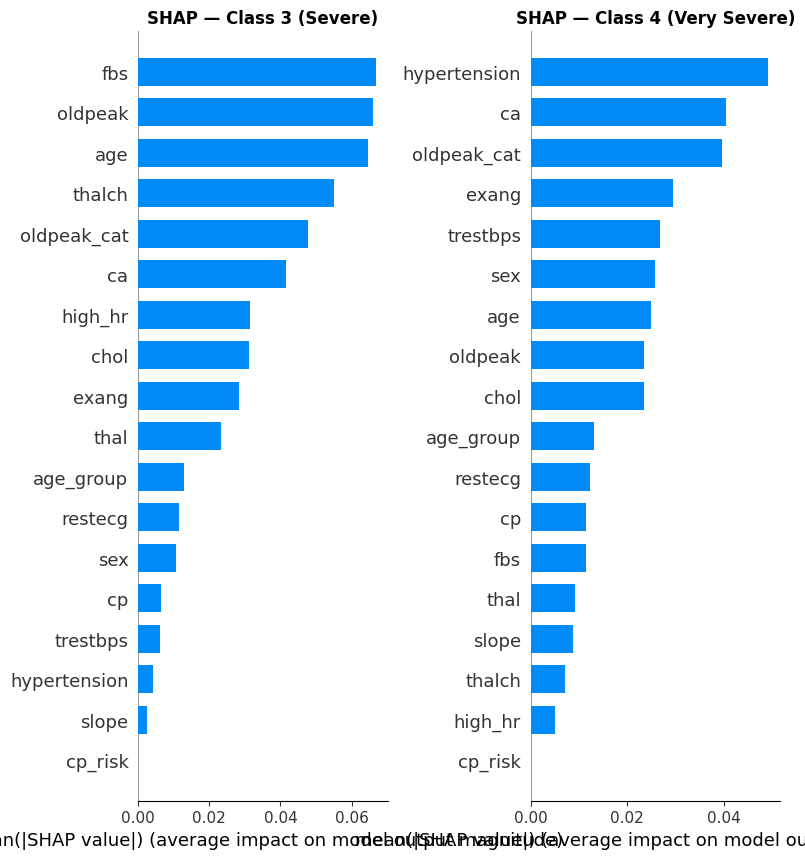

  SHAP plot saved → shap_summary.png


In [ ]:
!pip install shap
print("\n" + "─" * 65)
print("STEP 12 │ SHAP EXPLAINABILITY")
print("─" * 65)

try:
    import shap

    preprocess_step = best_model.named_steps["preprocess"]
    smote_step = best_model.named_steps["smote"]
    scaler_step = best_model.named_steps["scaler"]
    clf_step = best_model.named_steps["clf"]

    X_preprocessed = preprocess_step.transform(X_train)
    X_sm, y_sm = smote_step.fit_resample(X_preprocessed, y_train)
    X_sm_scaled = scaler_step.transform(X_sm)

    if best_model_name == "Random Forest":
        explainer = shap.TreeExplainer(clf_step)
        shap_values = explainer.shap_values(X_sm_scaled[:500])
    else:
        bg = shap.sample(X_sm_scaled, 100)
        explainer = shap.KernelExplainer(clf_step.predict_proba, bg)
        shap_values = explainer.shap_values(X_sm_scaled[:100])

    SHAP_FEATURE_NAMES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for i, cls in enumerate([3, 4]):
        plt.sca(axes[i])
        sv = shap_values[cls] if isinstance(shap_values, list) else shap_values[:, :, cls]
        shap.summary_plot(
            sv, X_sm_scaled[:sv.shape[0]],
            feature_names=SHAP_FEATURE_NAMES,
            show=False, plot_type="bar",
        )
        axes[i].set_title(f"SHAP — Class {cls} ({CLASS_NAMES[cls]})", fontweight="bold")
    plt.tight_layout()
    plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("  SHAP plot saved → shap_summary.png")

except ImportError:
    print("  shap not installed  →  pip install shap")
    print("  (Skipping SHAP; all other results remain valid)")


## Step 14: Final Holdout Evaluation

Evaluate all models on the locked holdout set (honest test never seen during training).

In [ ]:
print("\n" + "─" * 65)
print("STEP 13 │ FINAL HOLDOUT EVALUATION")
print("─" * 65)
print("  ↳ These numbers were never used in any training decision or threshold tuning.\n")

summary_rows = []

for name, model in fitted_models.items():
    y_pred_std   = model.predict(X_holdout)
    y_pred_tuned = predict_with_thresholds(model, X_holdout, best_thresholds)

    row = {
        "Model":               name,
        "Acc (std)":           accuracy_score(y_holdout, y_pred_std),
        "Acc (tuned)":         accuracy_score(y_holdout, y_pred_tuned),
        "Macro-F1 (std)":      f1_score(y_holdout, y_pred_std,   average="macro", zero_division=0),
        "Macro-F1 (tuned)":    f1_score(y_holdout, y_pred_tuned, average="macro", zero_division=0),
        "Severity-F1 (std)":   severity_weighted_f1(y_holdout, y_pred_std),
        "Severity-F1 (tuned)": severity_weighted_f1(y_holdout, y_pred_tuned),
    }
    summary_rows.append(row)

    print(f"\n  ── {name} ────────────────────────────────────────")
    print(f"  Standard  → Acc: {row['Acc (std)']:.4f}  "
          f"Macro-F1: {row['Macro-F1 (std)']:.4f}  "
          f"Severity-F1: {row['Severity-F1 (std)']:.4f}")
    print(f"  Tuned     → Acc: {row['Acc (tuned)']:.4f}  "
          f"Macro-F1: {row['Macro-F1 (tuned)']:.4f}  "
          f"Severity-F1: {row['Severity-F1 (tuned)']:.4f}")
    print(f"\n  Classification report (tuned):")
    print(classification_report(
        y_holdout, y_pred_tuned,
        target_names=CLASS_NAMES,
        zero_division=0, digits=3,
    ))

results_df = pd.DataFrame(summary_rows)
print("\n  SUMMARY TABLE")
print(results_df.to_string(index=False))

## Step 15: Result Visualisations

Generate comprehensive visualizations for model performance and explainability.


─────────────────────────────────────────────────────────────────
STEP 14 │ RESULT VISUALISATIONS
─────────────────────────────────────────────────────────────────



─────────────────────────────────────────────────────────────────
STEP 14 │ RESULT VISUALISATIONS
─────────────────────────────────────────────────────────────────


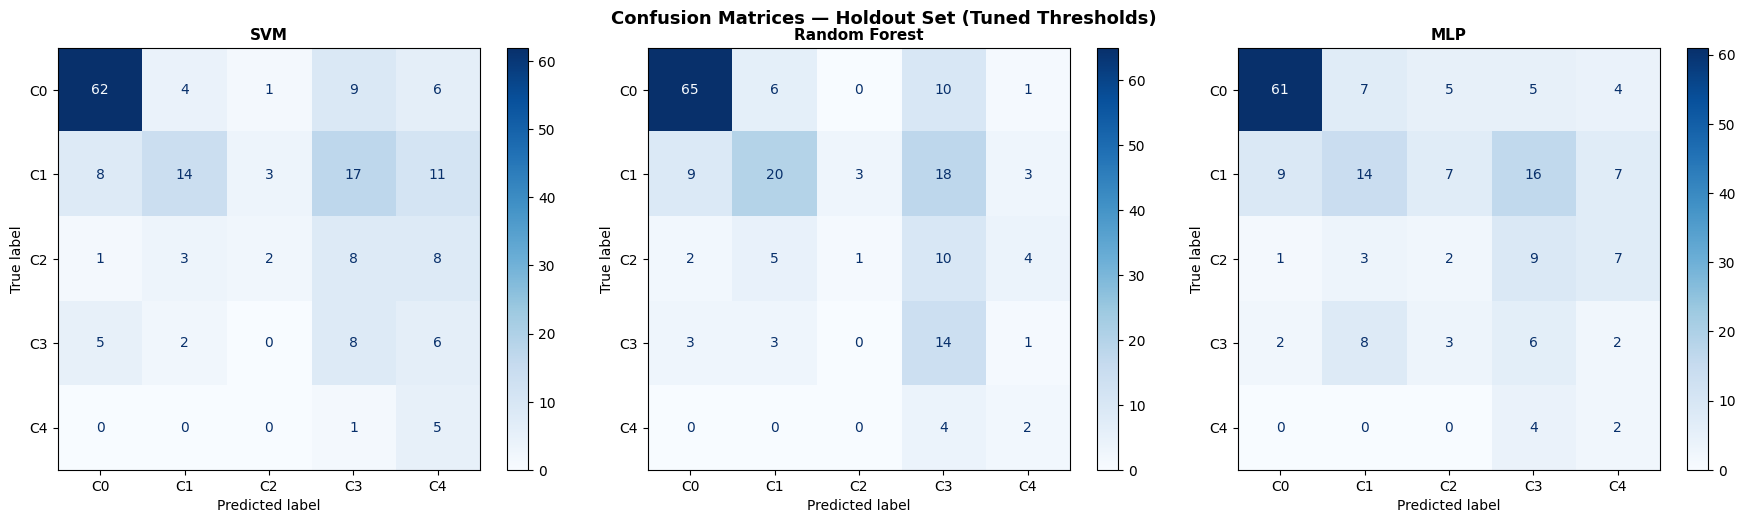


─────────────────────────────────────────────────────────────────
STEP 14 │ RESULT VISUALISATIONS
─────────────────────────────────────────────────────────────────


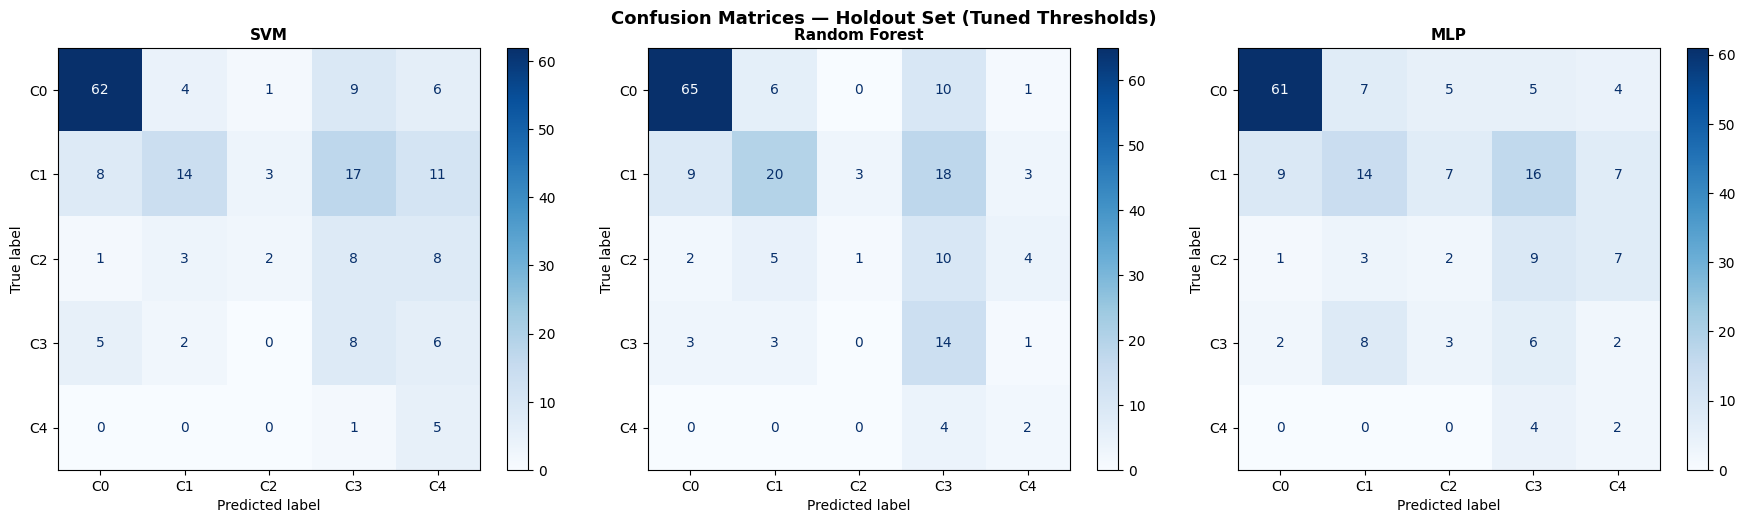

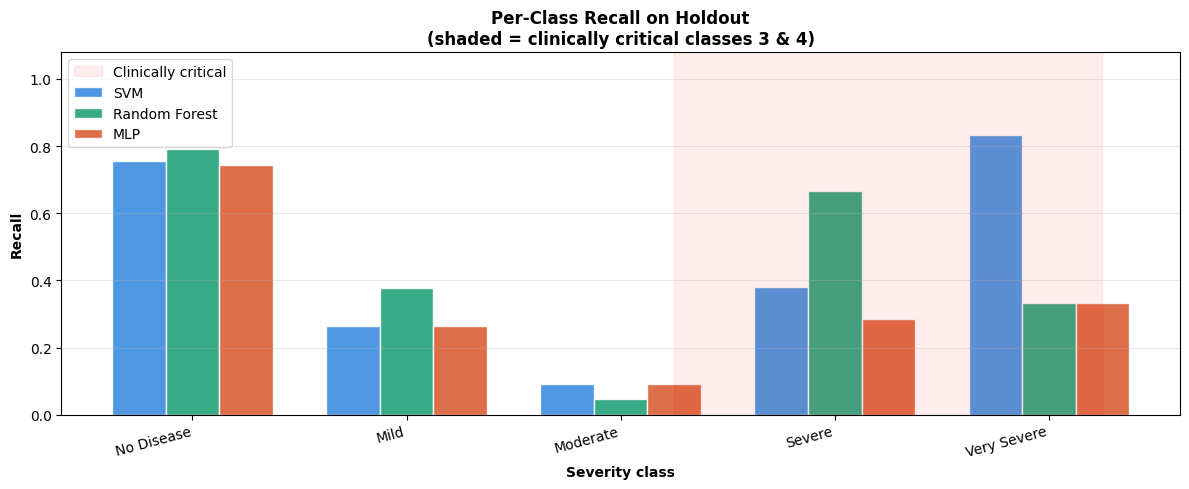


─────────────────────────────────────────────────────────────────
STEP 14 │ RESULT VISUALISATIONS
─────────────────────────────────────────────────────────────────


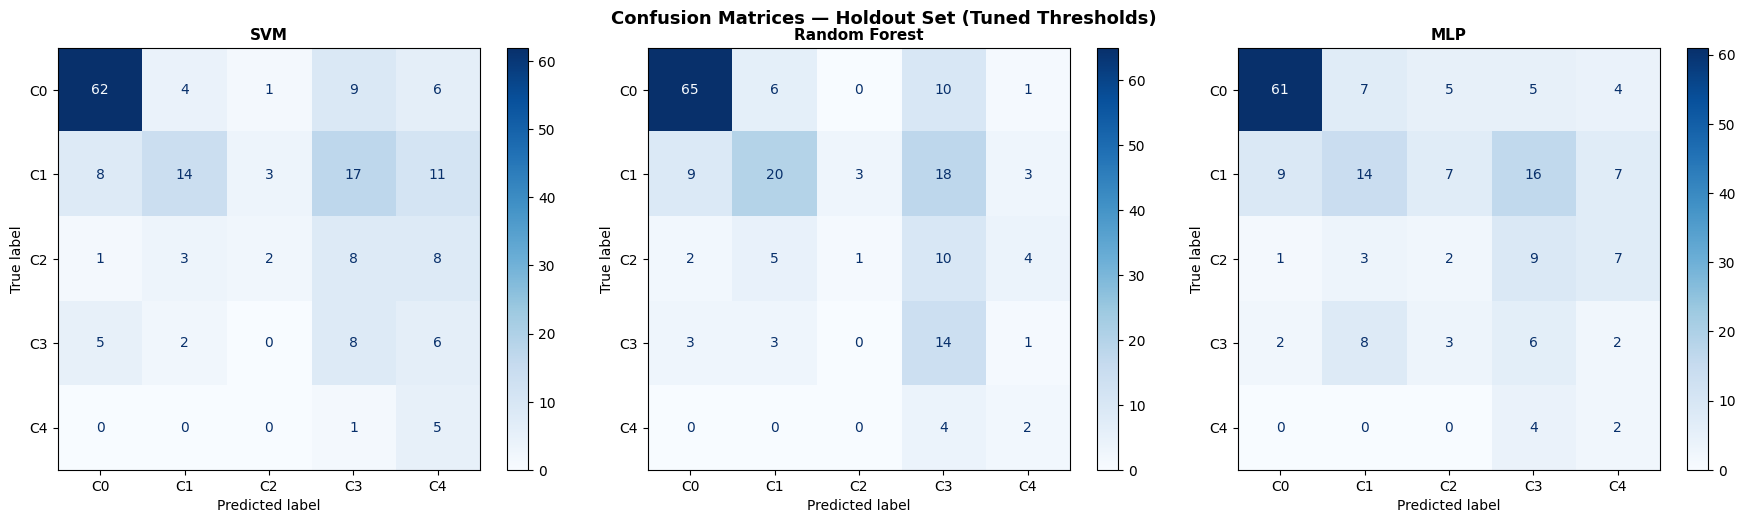

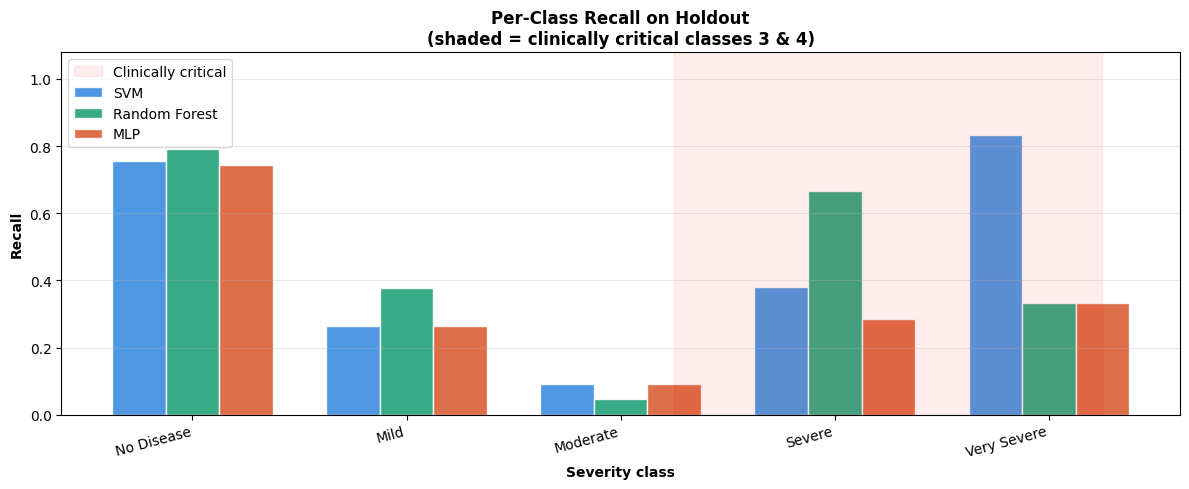

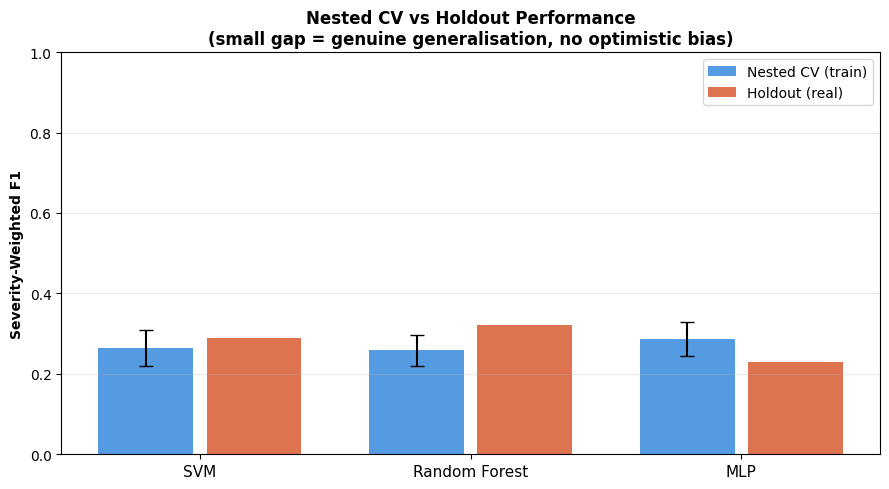


─────────────────────────────────────────────────────────────────
STEP 14 │ RESULT VISUALISATIONS
─────────────────────────────────────────────────────────────────


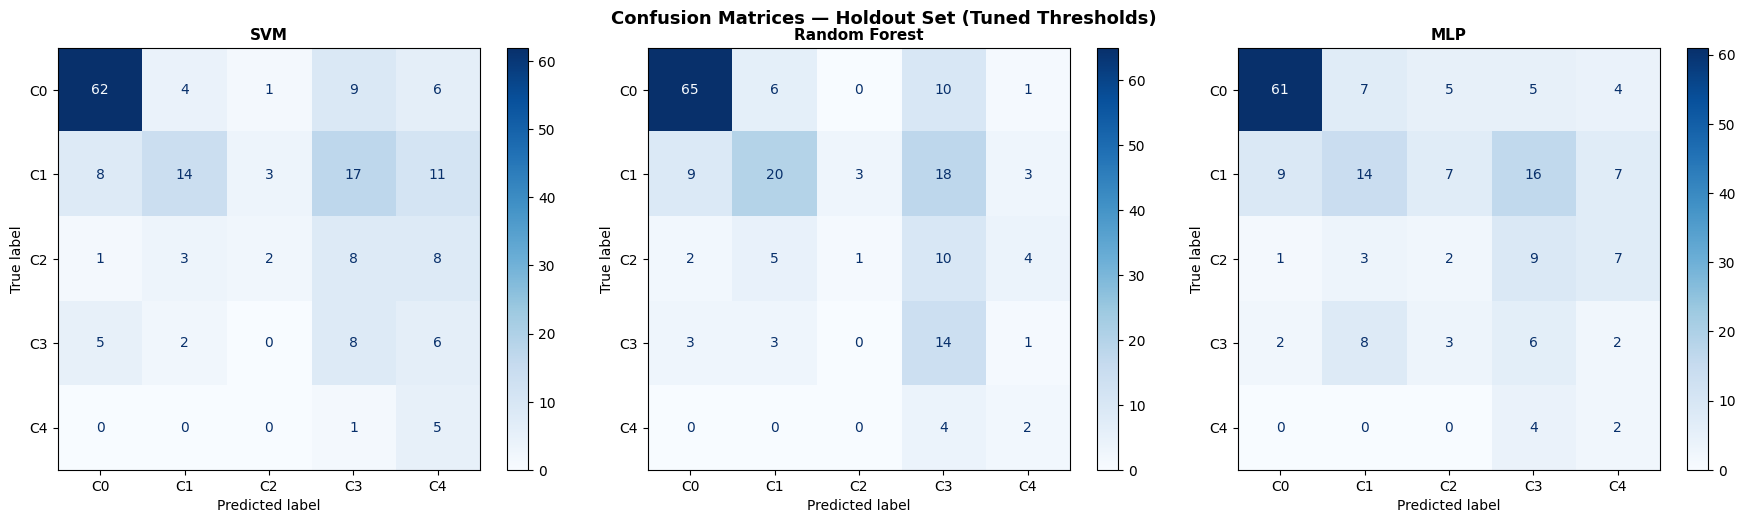

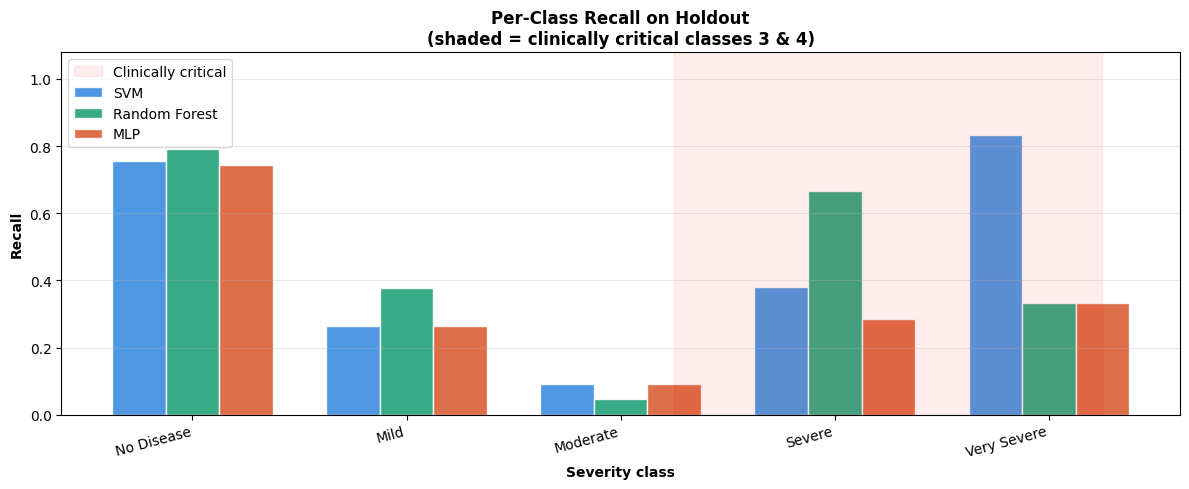

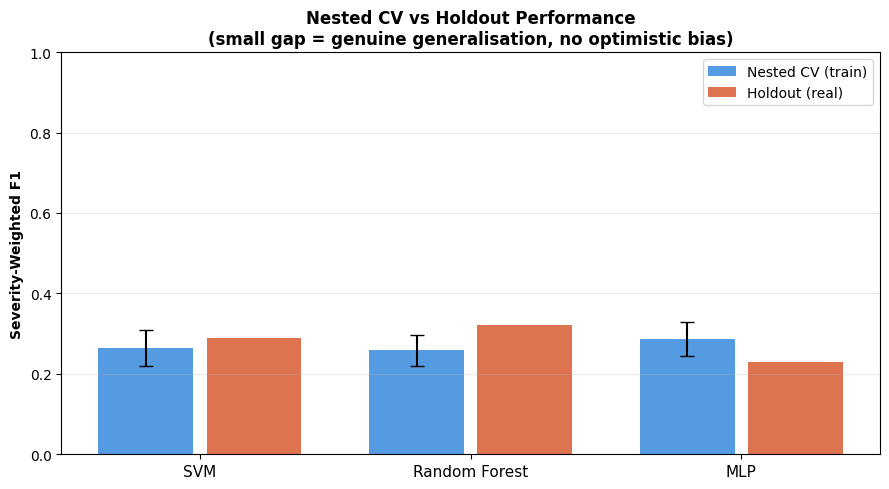

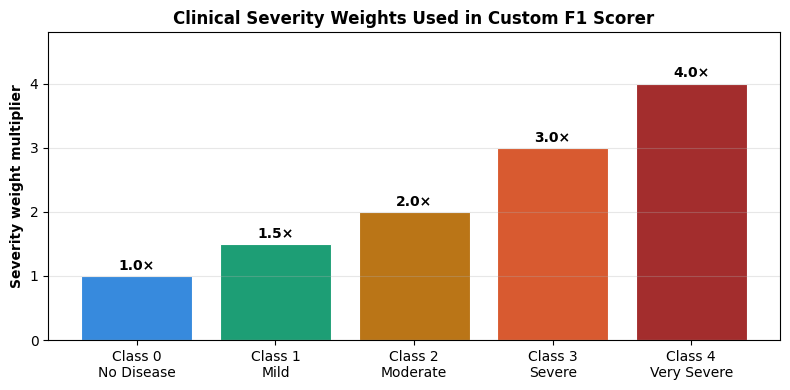

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 15. VISUALISATIONS
# ─────────────────────────────────────────────────────────────────────────────

print("\n" + "─" * 65)
print("STEP 14 │ RESULT VISUALISATIONS")
print("─" * 65)

# ── 15a. Confusion matrices ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Confusion Matrices — Holdout Set (Tuned Thresholds)",
             fontsize=13, fontweight="bold")

for ax, (name, model) in zip(axes, fitted_models.items()):
    y_pred = predict_with_thresholds(model, X_holdout, best_thresholds)
    cm     = confusion_matrix(y_holdout, y_pred)
    disp   = ConfusionMatrixDisplay(cm, display_labels=["C0","C1","C2","C3","C4"])
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    ax.set_title(f"{name}", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 15b. Per-class recall comparison ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
x       = np.arange(5)
width   = 0.25
palette = ["#378ADD", "#1D9E75", "#D85A30"]

for i, (name, model) in enumerate(fitted_models.items()):
    y_pred = predict_with_thresholds(model, X_holdout, best_thresholds)
    _, rec, _, _ = precision_recall_fscore_support(
        y_holdout, y_pred, labels=[0,1,2,3,4], zero_division=0
    )
    ax.bar(x + i * width, rec, width, label=name,
           color=palette[i], alpha=0.88, edgecolor="white")

ax.axvspan(2.5, 4.5, alpha=0.07, color="red", label="Clinically critical")
ax.set_xticks(x + width)
ax.set_xticklabels(CLASS_NAMES, rotation=15, ha="right")
ax.set_xlabel("Severity class", fontweight="bold")
ax.set_ylabel("Recall", fontweight="bold")
ax.set_title("Per-Class Recall on Holdout\n(shaded = clinically critical classes 3 & 4)",
             fontweight="bold")
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("recall_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 15c. Nested CV vs Holdout — honest generalisation gap ────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
model_names = list(nested_results.keys())
cv_means  = [nested_results[m]["test_severity_f1"].mean() for m in model_names]
cv_stds   = [nested_results[m]["test_severity_f1"].std()  for m in model_names]

# Calculate holdout severity-F1 scores directly from fitted models
hold_vals = []
for name in model_names:
    y_pred_tuned = predict_with_thresholds(fitted_models[name], X_holdout, best_thresholds)
    score = severity_weighted_f1(y_holdout, y_pred_tuned)
    hold_vals.append(score)

x = np.arange(len(model_names))
ax.bar(x - 0.2, cv_means,  0.35, yerr=cv_stds, capsize=5,
       label="Nested CV (train)", color="#378ADD", alpha=0.85)
ax.bar(x + 0.2, hold_vals, 0.35,
       label="Holdout (real)",    color="#D85A30", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylabel("Severity-Weighted F1", fontweight="bold")
ax.set_title("Nested CV vs Holdout Performance\n(small gap = genuine generalisation, no optimistic bias)",
             fontweight="bold")
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("cv_vs_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 15d. Severity weight visualisation ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
cls_labels = [f"Class {i}\n{CLASS_NAMES[i]}" for i in range(5)]
weights    = [SEV_WEIGHTS[i] for i in range(5)]
bars       = ax.bar(cls_labels, weights,
                    color=["#378ADD","#1D9E75","#BA7517","#D85A30","#A32D2D"],
                    edgecolor="white", linewidth=0.8)
for bar, w in zip(bars, weights):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{w}×", ha="center", va="bottom", fontweight="bold", fontsize=10)
ax.set_ylabel("Severity weight multiplier", fontweight="bold")
ax.set_title("Clinical Severity Weights Used in Custom F1 Scorer",
             fontweight="bold")
ax.set_ylim(0, 4.8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("severity_weights.png", dpi=150, bbox_inches="tight")
plt.show()